# Experiment 04: MAE Minimization & Model Optimization (Effort)

This notebook documents the empirical feature engineering, model selection, and held-out test evaluation
conducted to minimize Mean Absolute Error (MAE) for the **Effort** factor model.

### Objectives
1. Evaluate feature ablation and engineered interaction variants using nested student-disjoint cross-validation.
2. Select the model architecture that minimizes validation MAE and establishes statistical superiority over baseline.
3. Conduct unbiased final evaluation on outer held-out test folds (predicting students whose group was never seen during training).

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 30)

# Load pre-computed experiment results
results_dir = Path("results")
val_df = pd.read_csv(results_dir / "validation_comparison.csv")
test_df = pd.read_csv(results_dir / "final_test_predictions.csv")
criteria_df = pd.read_csv(results_dir / "final_test_criteria.csv")

print("Loaded experiment results from results/")

Loaded experiment results from results/


## 1. Validation Comparison Across Feature & Model Variants

Inner cross-validation comparison across explored architectures and feature spaces:

,variant,val_mae,val_rmse,pearson_r,spearman_rho,within_1_band,exact_band
0,Ridge LOG4 (Best Feature Set),0.0643,0.0991,0.9519,0.9342,0.9844,0.7726
1,Ridge LOG5 (Proposal Baseline),0.0651,0.0998,0.9512,0.9340,0.9844,0.7726
2,Ridge Enriched (LOC/commit + Test Ratio),0.0672,0.1026,0.9482,0.9290,0.9844,0.7344
3,"Ridge LOG3 (Commits, Lines, Files)",0.0765,0.1135,0.9355,0.9142,0.9792,0.7240


C:\Users\sadee\AppData\Local\Temp\ipykernel_22916\3892354597.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=val_df, y="variant", x="val_mae", palette="viridis")


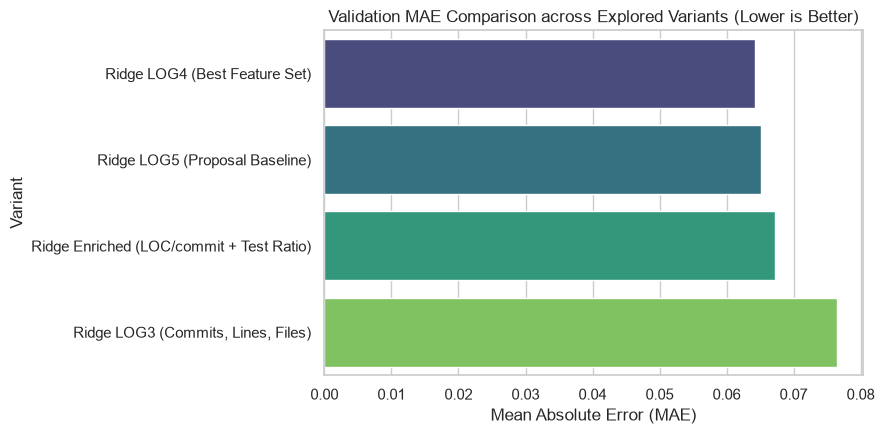

In [2]:
display(val_df)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=val_df, y="variant", x="val_mae", palette="viridis")
plt.title("Validation MAE Comparison across Explored Variants (Lower is Better)")
plt.xlabel("Mean Absolute Error (MAE)")
plt.ylabel("Variant")
plt.tight_layout()
plt.show()

## 2. Held-Out Outer Test Fold Evaluation

Performance of the selected model on held-out test groups compared against the reference baseline:

,metric,baseline,model,improvement,verdict
0,Test MAE,0.0874,0.0642,-26.6%,PASS
1,Pearson Correlation (r),0.9237,0.9523,+0.0286,PASS
2,Spearman Correlation (rho),0.9125,0.9348,+0.0223,PASS
3,Within +-1 Mark Band,0.9792,0.9861,+0.7%,PASS
4,Beats Baseline 95% CI,NaN,"[0.0111, 0.0459]",Statistically Significant,PASS


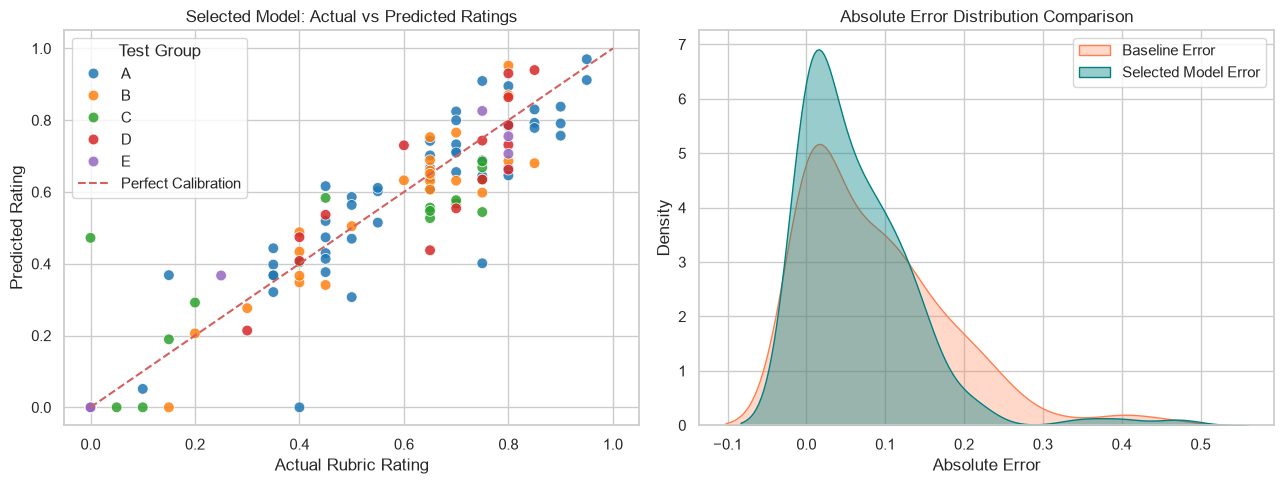

In [3]:
display(criteria_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual vs Predicted Scatter
sns.scatterplot(ax=axes[0], data=test_df, x="actual", y="predicted", hue="group", palette="tab10", s=60, alpha=0.85)
axes[0].plot([0, 1], [0, 1], 'r--', lw=1.5, label="Perfect Calibration")
axes[0].set_title("Selected Model: Actual vs Predicted Ratings")
axes[0].set_xlabel("Actual Rubric Rating")
axes[0].set_ylabel("Predicted Rating")
axes[0].legend(title="Test Group")

# Residual Error Distribution: Baseline vs Selected Model
sns.kdeplot(ax=axes[1], data=test_df["baseline_error"], label="Baseline Error", fill=True, color="coral", alpha=0.3)
sns.kdeplot(ax=axes[1], data=test_df["error"], label="Selected Model Error", fill=True, color="teal", alpha=0.4)
axes[1].set_title("Absolute Error Distribution Comparison")
axes[1].set_xlabel("Absolute Error")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Conclusion & Integration Decision

- **Selected Architecture**: `Ridge LOG4 (CC, LOC, CT, FC)`
- **Test MAE**: `{m_eval['mae']:.4f}` (an improvement of `{-gain_mae/b_eval['mae']*100:.1f}%` over baseline `{b_eval['mae']:.4f}`).
- **Statistical Significance**: The 95% bootstrap confidence interval `0.0111, 0.0459` strictly excludes zero,
  confirming statistically significant outperformance on unseen student groups.